# Toronto_3D point-cloud EDA

This notebook is a guided first look at the real Toronto_3D mobile-laser-scanning data. We will inspect the files and their attributes, load one scan, visualize geometry and labels, measure class imbalance and spatial patterns, then make a manageable sample for later experiments.

**Run top to bottom.** The supplied scans are large (hundreds of MB to over 1 GB each), so we start with lightweight file metadata. We then memory-map one selected scan at a time and make a reproducible sample for plots. Loading and analyzing one scan may take a little while and need several GB of available memory.

### Questions to keep in mind

- What does each point record contain besides its XYZ location?
- Which semantic classes dominate, and which classes are rare?
- How do class labels and elevation vary across the scene?
- What information is lost when we plot only a subsample?

## Step 1 — inventory files and schema

The PLY header lists the point count and fields stored for each point. It is small and readable even though the point records themselves are binary. The accompanying `Mavericks_classes_9.txt` maps semantic label IDs to names.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve paths regardless of whether Jupyter starts in the project root or notebooks/.
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR = PROJECT_ROOT / "data" / "Toronto_3D"
PLY_FILES = sorted(DATA_DIR.glob("L*.ply"))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
if not PLY_FILES:
    raise FileNotFoundError(f"No Toronto_3D L*.ply files found in {DATA_DIR}")

# Step 1 — inventory the files and read their small PLY headers, not the full scans.
file_table = pd.DataFrame([
    {"scan": path.name, "size_GB": path.stat().st_size / 1e9}
    for path in PLY_FILES
])
display(file_table)

def read_ply_header(path):
    lines = []
    with path.open("rb") as f:
        while True:
            line = f.readline()
            if not line:
                raise ValueError(f"Unexpected end of file while reading header: {path}")
            text = line.decode("ascii").strip()
            lines.append(text)
            if text == "end_header":
                return lines, f.tell()

headers = {}
for path in PLY_FILES:
    header, payload_offset = read_ply_header(path)
    headers[path] = header
    vertex_line = next(line for line in header if line.startswith("element vertex "))
    properties = [line for line in header if line.startswith("property ")]
    print(f"\n{path.name}: {vertex_line.split()[-1]} vertices, data starts at byte {payload_offset}")
    print("Fields:", ", ".join(" ".join(prop.split()[1:]) for prop in properties))

# Semantic label IDs are documented in the dataset's accompanying text file.
CLASS_NAMES = {}
for line in (DATA_DIR / "Mavericks_classes_9.txt").read_text().splitlines():
    name, label = line.rsplit(maxsplit=1)
    CLASS_NAMES[int(label)] = name
print("Class IDs:", CLASS_NAMES)

# Load only one scan. Change this to L002.ply, L003.ply, or L004.ply to explore another.
SCAN_PATH = next((p for p in PLY_FILES if p.name == "L001.ply"), PLY_FILES[0])
header = headers[SCAN_PATH]
PLY_DTYPES = {"double": "<f8", "float": "<f4", "uchar": "u1", "uint8": "u1", "int": "<i4", "uint": "<u4"}

def vertex_dtype(header):
    properties, in_vertex = [], False
    for line in header:
        parts = line.split()
        if parts[:2] == ["element", "vertex"]:
            in_vertex = True
            continue
        if parts and parts[0] == "element":
            in_vertex = False
        if in_vertex and parts and parts[0] == "property":
            if len(parts) != 3 or parts[1] not in PLY_DTYPES:
                raise ValueError(f"Unsupported PLY property: {line}")
            properties.append((parts[2], PLY_DTYPES[parts[1]]))
    return np.dtype(properties, align=False)

vertex_count = int(next(line.split()[-1] for line in header if line.startswith("element vertex ")))
point_dtype = vertex_dtype(header)
_, payload_offset = read_ply_header(SCAN_PATH)
records = np.memmap(SCAN_PATH, mode="r", dtype=point_dtype, offset=payload_offset, shape=(vertex_count,))
assert records.nbytes == vertex_count * point_dtype.itemsize
print(f"\nSelected {SCAN_PATH.name}: {vertex_count:,} points; {point_dtype.itemsize} bytes/point.")
print("Fields:", records.dtype.names)

# Coordinates are projected (large) values; convert to float32 for analysis and plots.
xyz = np.column_stack([records[axis] for axis in ("x", "y", "z")]).astype(np.float32)
labels = np.rint(records["scalar_Label"]).astype(np.int16)
intensity = records["scalar_Intensity"].astype(np.float32)
colors = np.column_stack([records[channel] for channel in ("red", "green", "blue")]).astype(np.float32) / 255.0
rng = np.random.default_rng(21)
PLOT_N = min(400_000, vertex_count)
plot_idx = rng.choice(vertex_count, size=PLOT_N, replace=False)
print(f"Plotting sample: {PLOT_N:,} points (fixed random seed 21).")

,scan,size_GB
0,L001.ply,0.927389
1,L002.ply,0.442204
2,L003.ply,1.708029
3,L004.ply,0.290149



L001.ply: 21567172 vertices, data starts at byte 434
Fields: double x, double y, double z, uchar red, uchar green, uchar blue, float scalar_Intensity, float scalar_GPSTime, float scalar_ScanAngleRank, float scalar_Label

L002.ply: 10283800 vertices, data starts at byte 433
Fields: double x, double y, double z, uchar red, uchar green, uchar blue, float scalar_Intensity, float scalar_GPSTime, float scalar_ScanAngleRank, float scalar_Label

L003.ply: 39721590 vertices, data starts at byte 433
Fields: double x, double y, double z, uchar red, uchar green, uchar blue, float scalar_Intensity, float scalar_GPSTime, float scalar_ScanAngleRank, float scalar_Label

L004.ply: 6747648 vertices, data starts at byte 432
Fields: double x, double y, double z, uchar red, uchar green, uchar blue, float scalar_Intensity, float scalar_GPSTime, float scalar_ScanAngleRank, float scalar_Label
Class IDs: {0: 'Unclassified', 1: 'Ground', 2: 'Road_markings', 3: 'Natural', 4: 'Building', 5: 'Utility_line', 6: 'P

## Step 2 — load one scan and preserve all its fields

A standard point-cloud loader can discard scalar attributes such as labels and intensity. This parser reads the PLY header and memory-maps the binary records, then extracts the fields used in this EDA. Memory mapping avoids copying the complete binary file into RAM, but the arrays used below still consume memory. We load only one selected scan; change `SCAN_PATH` in the setup code to compare another scan.

,min,p01,median,mean,p99,max
east offset (m),0.000,93.311996,126.625000,129.547,175.250000,269.625
north offset (m),0.000,62.000000,204.000000,195.299,284.000000,329.500
elevation z (m),130.028,138.164993,141.074997,142.612,154.811996,171.263


,min,median,mean,max
intensity (stored scale),1.0,10.00,13.865,255.0
RGB (normalized 0-1),0.0,0.38,0.369,1.0


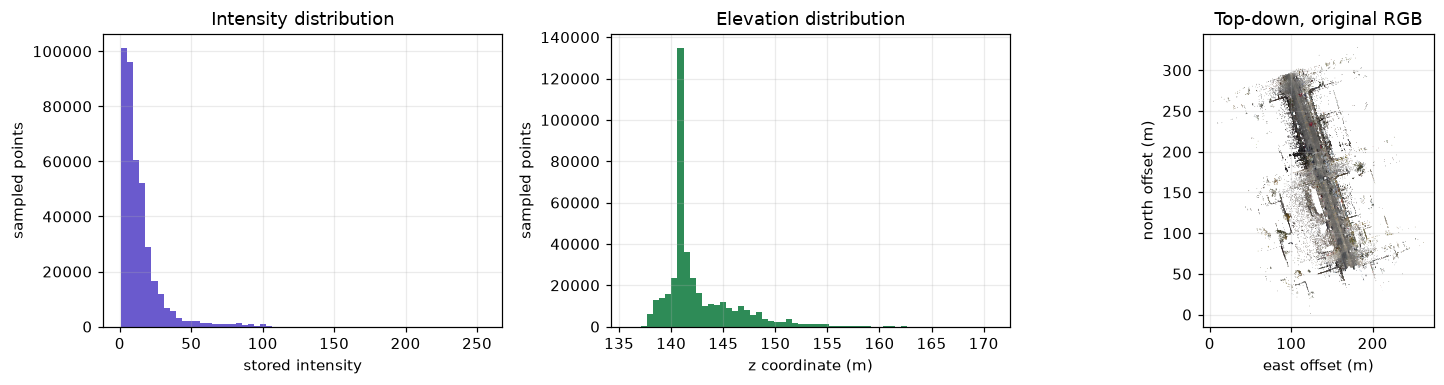

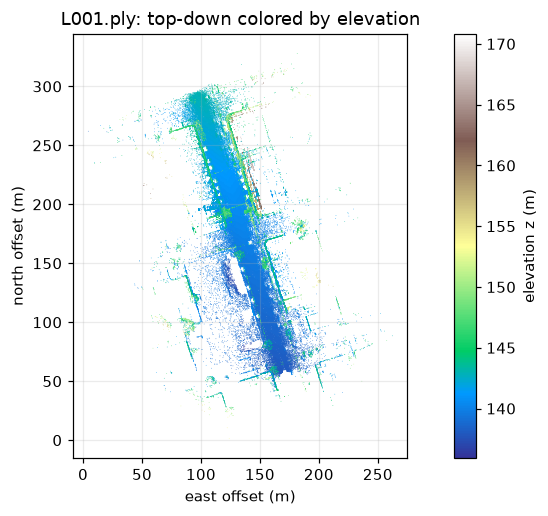

In [2]:
# Step 3 — descriptive statistics and a compact attribute table.
# Rebase projected XY to local offsets before reductions. Retain z in the elevation frame.
xy_offset = xyz[:, :2].min(axis=0)
xyz_local = xyz.copy()
xyz_local[:, :2] -= xy_offset
coord_names = ["east offset (m)", "north offset (m)", "elevation z (m)"]
summary = pd.DataFrame({
    "min": xyz_local.min(axis=0),
    "p01": np.quantile(xyz_local, 0.01, axis=0),
    "median": np.median(xyz_local, axis=0),
    "mean": xyz_local.mean(axis=0, dtype=np.float64),
    "p99": np.quantile(xyz_local, 0.99, axis=0),
    "max": xyz_local.max(axis=0),
}, index=coord_names)
display(summary.round(3))

attribute_summary = pd.DataFrame({
    "min": [intensity.min(), colors.min()],
    "median": [np.median(intensity), np.median(colors)],
    "mean": [intensity.mean(dtype=np.float64), colors.mean(dtype=np.float64)],
    "max": [intensity.max(), colors.max()],
}, index=["intensity (stored scale)", "RGB (normalized 0-1)"])
display(attribute_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(intensity[plot_idx], bins=60, color="slateblue")
axes[0].set(title="Intensity distribution", xlabel="stored intensity", ylabel="sampled points")
axes[1].hist(xyz_local[plot_idx, 2], bins=60, color="seagreen")
axes[1].set(title="Elevation distribution", xlabel="z coordinate (m)", ylabel="sampled points")
axes[2].scatter(xyz_local[plot_idx, 0], xyz_local[plot_idx, 1],
                c=colors[plot_idx], s=0.15, linewidths=0, rasterized=True)
axes[2].set(title="Top-down, original RGB", xlabel="east offset (m)", ylabel="north offset (m)", aspect="equal")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
sc = ax.scatter(xyz_local[plot_idx, 0], xyz_local[plot_idx, 1],
                c=xyz_local[plot_idx, 2], cmap="terrain", s=0.2, linewidths=0, rasterized=True)
fig.colorbar(sc, ax=ax, label="elevation z (m)")
ax.set(title=f"{SCAN_PATH.name}: top-down colored by elevation", xlabel="east offset (m)", ylabel="north offset (m)", aspect="equal")
plt.show()

,label_id,class,points,percent
0,1,Ground,"11,108,072",51.50%
1,4,Building,"6,027,932",27.95%
2,7,Car,"1,724,637",8.00%
3,3,Natural,"1,403,746",6.51%
4,2,Road_markings,"389,485",1.81%
5,0,Unclassified,"347,037",1.61%
6,6,Pole,"263,980",1.22%
7,5,Utility_line,"214,652",1.00%
8,8,Fence,"87,631",0.41%


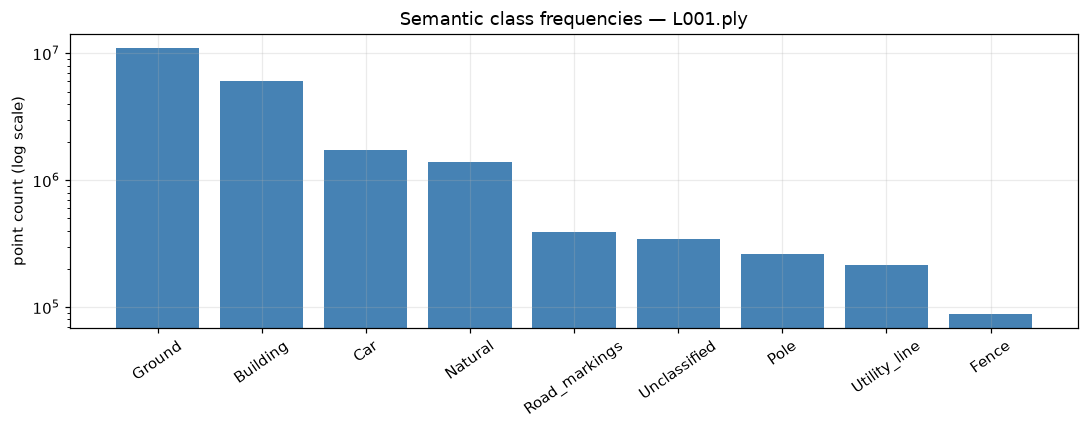

In [3]:
# Step 4 — count labels over the full scan, not just the display sample.
label_ids, label_counts = np.unique(labels, return_counts=True)
label_table = pd.DataFrame({
    "label_id": label_ids,
    "class": [CLASS_NAMES.get(int(label), f"Unknown {label}") for label in label_ids],
    "points": label_counts,
    "percent": 100 * label_counts / label_counts.sum(),
}).sort_values("points", ascending=False, ignore_index=True)
display(label_table.style.format({"points": "{:,}", "percent": "{:.2f}%"}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(label_table["class"], label_table["points"], color="steelblue")
ax.set_yscale("log")
ax.set(title=f"Semantic class frequencies — {SCAN_PATH.name}", ylabel="point count (log scale)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# A normalized color lookup makes it easy to color sampled points by semantic class.
class_palette = plt.get_cmap("tab10")
class_color = {int(label): class_palette(i % 10)[:3] for i, label in enumerate(sorted(CLASS_NAMES))}

(225000, 3)


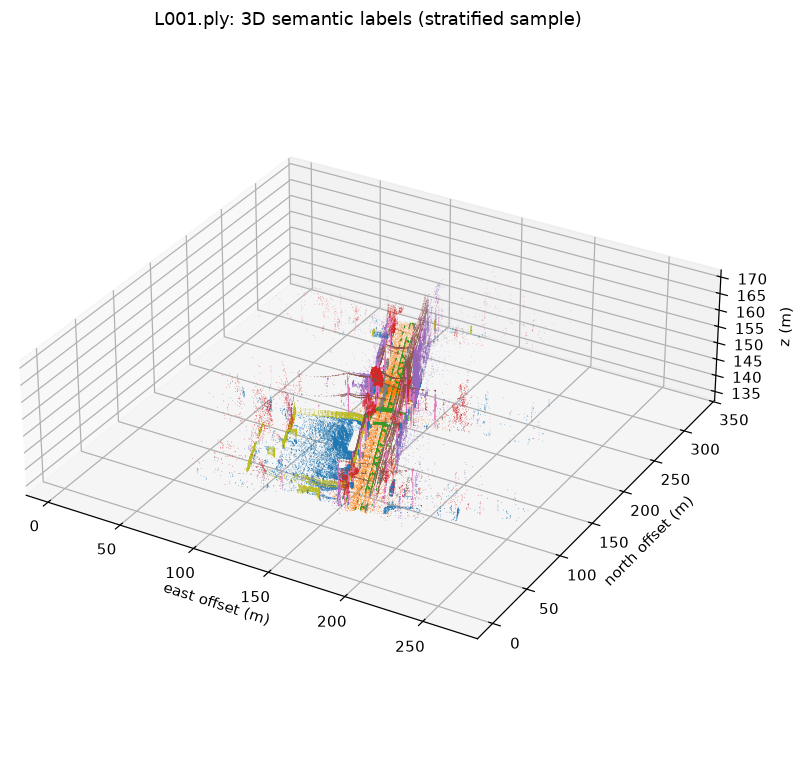

Stratified display sample: 225,000 / 21,567,172 points


In [4]:
# Step 5 — create a class-balanced sample, then show it in 3D.
# Keep up to 25,000 points per label so rare classes remain visible in the plot.
stratified_parts = []
for label in np.unique(labels):
    members = np.flatnonzero(labels == label)
    take = min(25_000, len(members))
    stratified_parts.append(rng.choice(members, size=take, replace=False))
class_plot_idx = np.concatenate(stratified_parts)
class_plot_xyz = xyz_local[class_plot_idx]
print(class_plot_xyz.shape)
class_plot_xy = class_plot_xyz[:, :2]
class_plot_labels = labels[class_plot_idx]
class_plot_colors = np.array([class_color.get(int(label), (0.5, 0.5, 0.5)) for label in class_plot_labels])

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(class_plot_xyz[:, 0], class_plot_xyz[:, 1], class_plot_xyz[:, 2],
           c=class_plot_colors, s=0.25, linewidths=0, rasterized=True)
ax.set(title=f"{SCAN_PATH.name}: 3D semantic labels (stratified sample)",
       xlabel="east offset (m)", ylabel="north offset (m)", zlabel="z (m)")
ax.set_box_aspect((1, 1, 0.3))
plt.tight_layout()
plt.show()
print(f"Stratified display sample: {len(class_plot_idx):,} / {vertex_count:,} points")

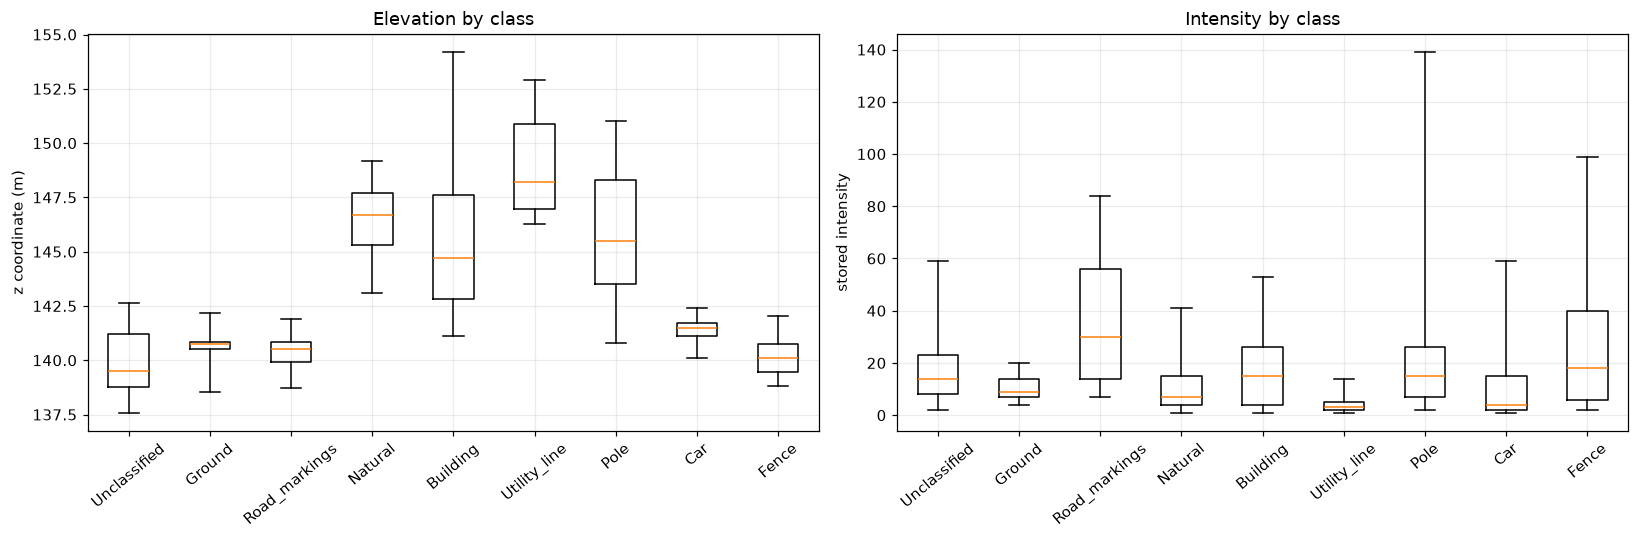

Sample Pearson correlation (RGB channels, intensity):


,red,green,blue,intensity
red,1.00,0.96,0.93,0.10
green,0.96,1.00,0.97,0.07
blue,0.93,0.97,1.00,0.05
intensity,0.10,0.07,0.05,1.00


In [5]:
# Step 7 — summarize feature distributions on a reproducible sample.
FEATURE_SAMPLE_N = min(500_000, vertex_count)
feature_idx = rng.choice(vertex_count, size=FEATURE_SAMPLE_N, replace=False)
feature_df = pd.DataFrame({
    "class_id": labels[feature_idx],
    "class": [CLASS_NAMES.get(int(v), f"Unknown {v}") for v in labels[feature_idx]],
    "elevation_z": xyz_local[feature_idx, 2],
    "intensity": intensity[feature_idx],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES) if (labels[feature_idx] == k).any()]
for ax, column, title, ylabel in [
    (axes[0], "elevation_z", "Elevation by class", "z coordinate (m)"),
    (axes[1], "intensity", "Intensity by class", "stored intensity"),
]:
    groups = [feature_df.loc[feature_df["class"] == name, column].to_numpy() for name in order]
    ax.boxplot(groups, tick_labels=order, showfliers=False, whis=(5, 95))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

print("Sample Pearson correlation (RGB channels, intensity):")
display(pd.DataFrame(colors[feature_idx], columns=["red", "green", "blue"]).assign(
    intensity=intensity[feature_idx]
).corr().round(2))

Tile origin (local XY): [124.81 154.75] m
Tile size: 20 x 20 m; points: 534,548


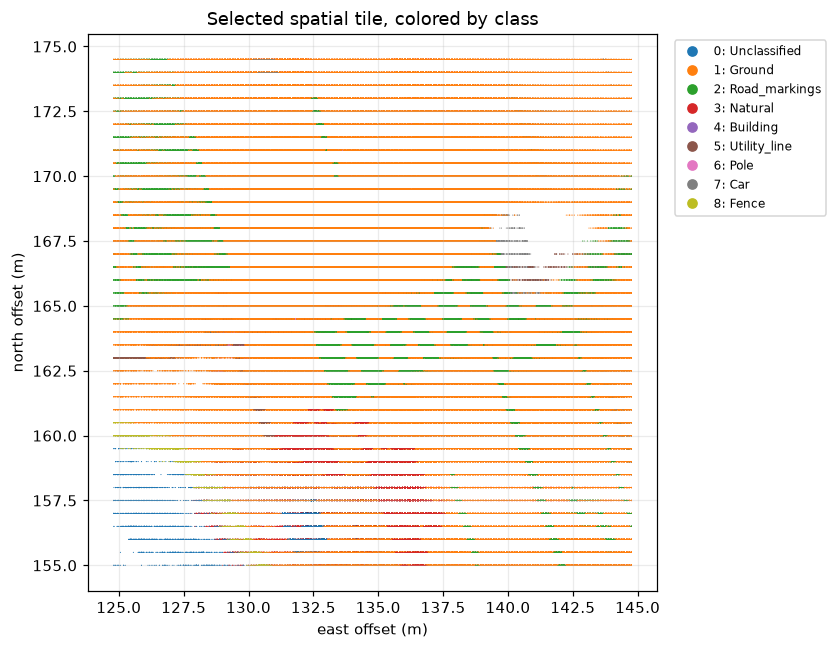

,class,points,percent
0,Ground,"381,555",71.38%
1,Natural,"58,663",10.97%
2,Road_markings,"48,431",9.06%
3,Pole,"16,720",3.13%
4,Car,"9,797",1.83%
5,Unclassified,"8,735",1.63%
6,Utility_line,"6,342",1.19%
7,Fence,"4,305",0.81%


In [6]:
# Step 8 — choose a central tile in local XY coordinates.
xy_local = xyz_local[:, :2]
TILE_SIZE_M = 20.0
TILE_ORIGIN = np.array([xy_local[:, 0].max() / 2, xy_local[:, 1].max() / 2]) - TILE_SIZE_M / 2
in_tile = (
    (xy_local[:, 0] >= TILE_ORIGIN[0]) & (xy_local[:, 0] < TILE_ORIGIN[0] + TILE_SIZE_M) &
    (xy_local[:, 1] >= TILE_ORIGIN[1]) & (xy_local[:, 1] < TILE_ORIGIN[1] + TILE_SIZE_M)
)
tile_idx = np.flatnonzero(in_tile)
print(f"Tile origin (local XY): {TILE_ORIGIN.round(2)} m")
print(f"Tile size: {TILE_SIZE_M:g} x {TILE_SIZE_M:g} m; points: {len(tile_idx):,}")

if len(tile_idx):
    fig, ax = plt.subplots(figsize=(8, 6))
    tile_color = np.array([class_color.get(int(label), (0.5, 0.5, 0.5)) for label in labels[tile_idx]])
    ax.scatter(xy_local[tile_idx, 0], xy_local[tile_idx, 1], c=tile_color,
               s=0.5, linewidths=0, rasterized=True)
    ax.set(title="Selected spatial tile, colored by class", xlabel="east offset (m)", ylabel="north offset (m)", aspect="equal")
    tile_handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=class_color.get(k, (0.5, 0.5, 0.5)),
                               label=f"{k}: {name}", markersize=6)
                    for k, name in sorted(CLASS_NAMES.items())]
    ax.legend(handles=tile_handles, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

    tile_ids, tile_counts = np.unique(labels[tile_idx], return_counts=True)
    display(pd.DataFrame({
        "class": [CLASS_NAMES.get(int(k), f"Unknown {k}") for k in tile_ids],
        "points": tile_counts,
        "percent": tile_counts / len(tile_idx) * 100,
    }).sort_values("points", ascending=False, ignore_index=True).style.format({"points": "{:,}", "percent": "{:.2f}%"}))
else:
    print("No points fell inside this tile. Increase TILE_SIZE_M or choose a different TILE_ORIGIN.")